In [3]:
#15.Split your data into three parts this time, training, validation, and test, and 
#keep the test part sealed until the very end of the day.
import seaborn as sb
from sklearn.model_selection import train_test_split
titanic=sb.load_dataset("titanic")
X = titanic.drop(["survived", "alive"], axis=1)
y = titanic["survived"]
X_temp,X_test,y_temp,y_test=train_test_split(X,y,test_size=0.15,random_state=42,stratify=y)
X_train,X_val,y_train,y_val=train_test_split(X_temp,y_temp,test_size=0.1765,random_state=42,stratify=y_temp)
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test.shape)

Training data: (623, 13)
Validation data: (134, 13)
Test data: (134, 13)


In [18]:
#16.Wrap your training and validation tensors in a TensorDataset and then in a DataLoader,
#shuffling the training one only.
import torch
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader
# Convert text columns into numbers
X_train = pd.get_dummies(X_train, dtype=int)
X_val = pd.get_dummies(X_val, dtype=int)
medians = X_train.median()
X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
# Convert into tensors
X_train_tensor = torch.tensor(X_train.to_numpy(dtype="float32"))
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.long)
X_val_tensor = torch.tensor(X_val.to_numpy(dtype="float32"))
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.long)
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
print("Everything is ready!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Everything is ready!
Training batches: 20
Validation batches: 5


Epoch 1/100 | Train Loss: 0.8845 | Validation Loss: 0.6350 | Validation Accuracy: 70.15%
Epoch 2/100 | Train Loss: 0.6197 | Validation Loss: 0.5549 | Validation Accuracy: 71.64%
Epoch 3/100 | Train Loss: 0.5829 | Validation Loss: 0.5269 | Validation Accuracy: 71.64%
Epoch 4/100 | Train Loss: 0.5655 | Validation Loss: 0.5220 | Validation Accuracy: 73.13%
Epoch 5/100 | Train Loss: 0.5474 | Validation Loss: 0.5069 | Validation Accuracy: 73.88%
Epoch 6/100 | Train Loss: 0.5304 | Validation Loss: 0.4927 | Validation Accuracy: 73.13%
Epoch 7/100 | Train Loss: 0.5181 | Validation Loss: 0.4757 | Validation Accuracy: 73.13%
Epoch 8/100 | Train Loss: 0.5063 | Validation Loss: 0.4743 | Validation Accuracy: 73.88%
Epoch 9/100 | Train Loss: 0.4974 | Validation Loss: 0.4575 | Validation Accuracy: 75.37%
Epoch 10/100 | Train Loss: 0.4891 | Validation Loss: 0.4480 | Validation Accuracy: 76.87%
Epoch 11/100 | Train Loss: 0.4791 | Validation Loss: 0.4490 | Validation Accuracy: 78.36%
Epoch 12/100 | Trai

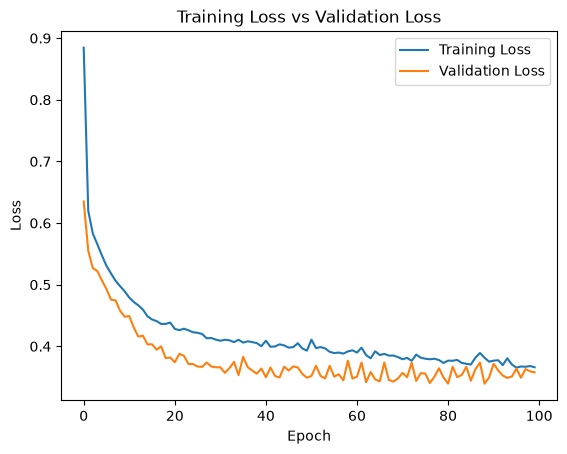

In [19]:
#18.At the end of every epoch, switch to eval mode, compute validation loss and
#accuracy with gradients disabled, then switch back to train mode.
#19.Store both losses every epoch and plot them together on one chart once training finishes.
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# 1. Create the model FIRST
input_features = X_train_tensor.shape[1]
model = nn.Sequential(nn.Linear(input_features, 32),nn.ReLU(),nn.Linear(32, 2))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_losses = []
val_losses = []
epochs = 100
for epoch in range(epochs):
    model.train()
    train_loss = 0
    train_total = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(y_batch)
        train_total += len(y_batch)
    train_loss = train_loss / train_total
    train_losses.append(train_loss)

    # 4. Validation after every epoch
    model.eval()
    val_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            predictions = model(X_batch)
            loss = loss_fn(predictions, y_batch)
            val_loss += loss.item() * len(y_batch)
            predicted_classes = predictions.argmax(dim=1)
            correct += (predicted_classes == y_batch).sum().item()
            total += len(y_batch)
    val_loss = val_loss / total
    val_accuracy = correct / total
    val_losses.append(val_loss)
    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy * 100:.2f}%")
# 5. Plot both losses after training
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs Validation Loss")
plt.legend()
plt.show()
